This implementation uses MTZ constraints instead of subtour elimination

Based on implementation given here: https://discourse.julialang.org/t/subtour-elimination-constraints/106902/11

In [1]:
using CSV, DataFrames, JuMP, Gurobi, Plots, Random
using LaTeXStrings, StatsPlots, LinearAlgebra

In [2]:
city_coords = CSV.read("data/cities.csv", DataFrame);
aircraft_costs = CSV.read("data/costs11.csv", DataFrame);
aircraft_ranges = CSV.read("data/ranges11.csv", DataFrame);

In [3]:
C = Matrix(city_coords);
C = C[1:size(C,1)-1,:];
O = Matrix(aircraft_costs);
R = Matrix(aircraft_ranges);

In [4]:
# Define distance function
function distance(x_1::Float64, y_1::Float64, x_2::Float64, y_2::Float64)::Float64
    deltax = x_1 - x_2;
    deltay = y_1 - y_2;
    d = sqrt(deltax^2 + deltay^2);
    return d
end

distance (generic function with 1 method)

In [5]:
function distance_matrix(C::Matrix)
    n = size(C,1)
    D = zeros((n,n))
    for i in 1:n
        for j in 1:n
            D[i,j] = distance(C[i,1],C[i,2],C[j,1],C[j,2])
        end
    end
    return D
end

distance_matrix (generic function with 1 method)

In [6]:
D = distance_matrix(C);

In [7]:
V = 1:size(C,1);
n = length(V);

In [8]:
model = Model(Gurobi.Optimizer);

Set parameter Username
Academic license - for non-commercial use only - expires 2024-09-07


In [9]:
@variable(model, X[i in V, j in V, k in 1:n], Bin);
@variable(model, Y[i in V, k in 1:n], Bin);
@variable(model, 2 <= U[i in V, k in 1:n] <= length(V));

In [10]:
fix.(U[1,:], 1; force = true);

In [11]:
@objective(
    model,
    Min,
    sum(O[k] * D[i, j] * X[i, j, k] for i in V, j in V, k in 1:n),
);

In [12]:
@constraints(model, begin
    # For all nodes and routes, flow out == flow in
    [i in V, k in 1:n], sum(X[i, :, k]) == sum(X[:, i, k])
    # Flow in and out of other nodes is 1
    [i in V; i != 1], sum(X[i, :, :]) == 1
    [i in V; i != 1], sum(X[:, i, :]) == 1
    # MTZ constraints
    [i in V, j in V, k in 1:n; i != 1 && j != 1],
        U[i, k] - U[j, k] + 1 <= (n - 1) * (1 - X[i, j, k])
    # y[i, k] is 1 if node i is in route k
    [i in V, k in 1:n], sum(X[i, :, k]) == Y[i, k]
    # each node can be in at most one route, except node 1, which is in every 
    # route
    [i in V; i != 1], sum(Y[i, :]) <= 1
    # Range constraint
    [i in V, j in V, k in 1:n], D[i,j] * X[i,j,k] <= R[k]
    end);

In [13]:
optimize!(model)
for k in 1:n
    print("Route $k: 1")
    i = 1
    while true
        for j in V
            if value(X[i, j, k]) > 0.5
                print(" => $j")
                i = j
                break
            end
        end
        if i == 1
            println()
            break
        end
    end
end

Gurobi Optimizer version 10.0.2 build v10.0.2rc0 (win64)

CPU model: 12th Gen Intel(R) Core(TM) i7-1255U, instruction set [SSE2|AVX|AVX2]
Thread count: 10 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 2703 rows, 1573 columns and 10692 nonzeros
Model fingerprint: 0xbb5a67ce
Variable types: 121 continuous, 1452 integer (1452 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+02]
  Objective range  [2e+00, 3e+02]
  Bounds range     [1e+00, 1e+01]
  RHS range        [1e+00, 8e+01]
Presolve removed 2283 rows and 1079 columns
Presolve time: 0.02s
Presolved: 420 rows, 494 columns, 4268 nonzeros
Variable types: 62 continuous, 432 integer (432 binary)

Root relaxation: objective 5.325827e+02, 38 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0  532.58274    0   20          -  532.58274    

In [14]:
Xopt = Array(value.(X[:,:,:]));

[1,7,2]
[4,1,2]
[7,8,2]
[8,4,2]
[1,2,5]
[2,3,5]
[3,1,5]
[1,10,9]
[5,9,9]
[6,11,9]
[9,6,9]
[10,5,9]
[11,1,9]


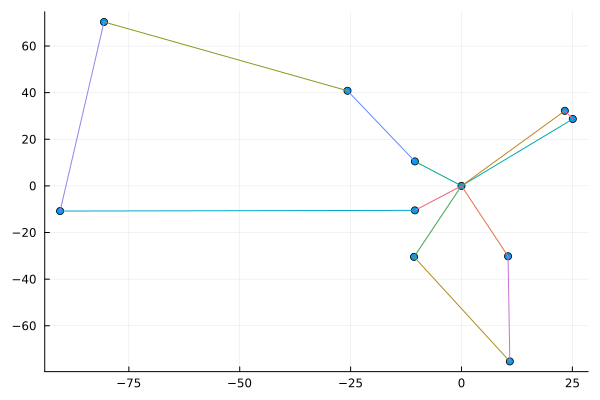

In [15]:
fig = scatter(C[:,1], C[:,2], legend=false);
for k in 1:n
    for i in V
        for j in V
            if (Xopt[i,j,k] > 0.95) 
                print("[" * string(i) * "," * string(j) * "," * string(k) * "]")
                print("\n")
                xcoords = [C[i,1];C[j,1]];
                ycoords = [C[i,2];C[j,2]];
 
                plot!(fig, xcoords, ycoords);
            end
        end
    end
end
fig